# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ShayanAhmed12/flyrank-internship-ml/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

**Which already-visible pages are under-capturing clicks for their search position, and which should an editor review first?**

- **Decision supported:** where a content/SEO editor spends a limited weekly review budget (≈20–50 pages).
- **Lane:** CTR / Engagement Opportunity Scoring (locked in Week 4).
- **Output:** a ranked review queue with one reason code and one action per page, framed as decision support, not as a causal claim.
- **Deployed paper:** see `submission/paper_url.txt`. This notebook mirrors it section by section and rebuilds its charts from the committed metric receipts in `work/outputs/*.json`.


In [1]:
import os, sys, json, shutil, subprocess
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
from IPython.display import Image, display
if "google.colab" in sys.modules:
    if not os.path.isdir("flyrank-ml-internship-starter"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/flyrank-bih/flyrank-ml-internship-starter"], check=True)
    os.chdir("flyrank-ml-internship-starter")
else:
    while not os.path.isdir("work") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")

R = {k: json.load(open(f"work/outputs/{f}")) for k, f in {
    "baseline": "w04_baseline_metrics.json", "model": "w05_model_metrics.json",
    "validation": "w06_validation_metrics.json", "playbook": "w07_playbook_metrics.json"}.items()}
print("Receipts loaded:", ", ".join(f"{k} ({len(json.dumps(v))} bytes)" for k, v in R.items()))


Receipts loaded: baseline (372 bytes), model (687 bytes), validation (1007 bytes), playbook (2693 bytes)


## 2. Data

- **Release:** FlyRank internship warehouse on Hugging Face (`FlyRank/internship-warehouse`, build `v20260703`), pseudonymised.
- **Tables:** `fact_content_daily_performance` (one row = one page per day; ~78.8M rows overall), joined to `dim_content` for content type, intent and creation date.
- **Windows:** development on **March 2026** (decision day 16 Mar: features 1–15, outcome 16–31); time-forward test on **April 2026** (decision day 16 Apr). **June 2026 is sealed** and never used.
- **Population:** pages with `gsc_data_available IS TRUE`, average position 1–20, ≥100 impressions in both halves of the month (57,392 pages from 36 clients in March; 59,532 from 43 in April).
- **Excluded:** GA4 columns (zero-filled before each client's GA4 start), `content_updated_date` (an export-time value after the decision day for 82% of pages), product-workflow date fields, keyword/URL hashes (grouping only). No client names, URLs or queries exist in the release, and none appear here.


In [2]:
print("March slice (from receipts):", R["baseline"]["slice"])
print(f"  pages {R['baseline']['pages']:,} | clients {R['baseline']['clients']} | label base rate {R['baseline']['base_rate']:.3f}")
print("Time-forward test:", R["validation"]["time_forward_test"])


March slice (from receipts): warehouse month=2026-03, decision 2026-03-16, features 1-15 Mar, outcome 16-31 Mar
  pages 57,392 | clients 36 | label base rate 0.398
Time-forward test: month=2026-04, decision 2026-04-16 (scored once)


## 3. Methodology

- **Label (proxy, observed in a later window):** `under_captures_next` = the page's CTR in days 16–end is below **half the median CTR of its position bucket** (1–3, 4–10, 11–20). It's a proxy for "keeps under-clicking", not "would gain clicks after a rewrite".
- **Features (days 1–15 only):** impressions (log), CTR, impression-weighted position, content type, age at decision day, plus the bucket-median expected CTR and the CTR/expected ratio.
- **Baseline (frozen Week 4):** pages with ≥500 impressions and CTR < 0.5 × expected; score = clicks at stake = (expected − actual CTR) × impressions; reason code `low_ctr_for_position`.
- **Models:** Logistic Regression, Random Forest, HistGradientBoosting (seed 42).
- **Validation:** GroupKFold(5) by client, plus a single frozen March→April time-forward test; metric = Precision@50 in the ≥500-impression pool, with ROC-AUC and base rates alongside.
- **Leakage checks:** deliberate leak (outcome CTR → AUC 1.000 in March, 0.997 April), single-feature AUC ceiling (max 0.739), creation dates before decision, outcome-window population filter disclosed (7% of pages).


In [3]:
print(json.dumps({k: R["model"][k] for k in ("split", "pool", "seed", "sklearn")}, indent=2))


{
  "split": "GroupKFold(5) by client_hash_id",
  "pool": "impr_f >= 500",
  "seed": 42,
  "sklearn": "1.9.1"
}


## 4. Results (vs baseline)

At the top of the queue the frozen rule and the best models are **tied** (P@50 ≈ 0.78 across client-grouped folds), and the rule is steadier across folds. The models rank the **whole list** much better (ROC-AUC 0.81 vs 0.55). A random page split overstated the forest by ~3 points. Frozen on March, both held on April (0.88 rule, 0.90 forest).


In [4]:
m = pd.DataFrame(R["model"]["table"]).set_index("method")
print("Client-grouped 5-fold, March (pool >= 500 impressions):"); print(m.round(3).to_string())
v = pd.DataFrame(R["validation"]["results"])
print("\nValidation designs:"); print(v.round(3).to_string(index=False))


Client-grouped 5-fold, March (pool >= 500 impressions):
                         P@50 mean  P@50 std  P@20 mean  ROC-AUC mean
method                                                               
Random pick (base rate)      0.248     0.081       0.33         0.503
Week-4 baseline              0.780     0.014       0.80         0.547
Logistic Regression          0.656     0.065       0.70         0.780
Random Forest                0.780     0.062       0.83         0.807
Gradient Boosting            0.776     0.062       0.82         0.806

Validation designs:
                       design        method   P50  P50_std   AUC  pool base rate
  BEFORE random-by-page (Mar) Random Forest 0.808    0.073 0.811           0.266
  BEFORE random-by-page (Mar)   Week-4 rule 0.732    0.059 0.550           0.266
AFTER grouped-by-client (Mar) Random Forest 0.780    0.062 0.807           0.266
AFTER grouped-by-client (Mar)   Week-4 rule 0.780    0.014 0.547           0.266
AFTER time-forward (Mar->Apr

## 5. Limitations

- One development month and one test month; 36–43 clients; a two-week outcome window.
- The label is a proxy, so no causal claim: the data can't show a rewrite *produces* clicks.
- Expected CTR drifted strongly March→April (−19% to −60% by bucket), so "clicks at stake" is a moving, upper-bound yardstick.
- The population needs outcome-window visibility (7% of pages dropped); there's a mild transductive effect in the bucket medians; concentration reaches 32–38% of the top 50 for one client.


In [5]:
trig = R["playbook"]["triggers"]
print("Monitoring triggers on the first run (March reference -> April):", trig)


Monitoring triggers on the first run (March reference -> April): {'queue_P@50_april': False, 'expected_ctr_max_change': True, 'psi (any)': False, 'base rate shift > 10pt': False, 'concentration > 50%': False}


## 6. Ranked recommendations

Archetype → action map (April queue). Every action needs a human check first; nothing is automated.


In [6]:
a = pd.DataFrame(R["playbook"]["archetypes"])
print(a.round(2).to_string(index=False))
print("\nCost / value by queue depth:")
print(pd.DataFrame(R["playbook"]["cost_value"]).to_string(index=False))


              archetype                  action  pages  clicks_at_stake_15d  model_agrees
 A broad-query mismatch    review_search_intent     49              2598.21          1.00
B top-3 zero-click risk check_serp_then_monitor   1033              3889.39          0.53
 C page-one snippet gap       review_title_meta   6726             20767.44          0.40
D striking-distance gap       improve_relevance   1959               785.34          0.26
    E top-3 snippet gap       review_title_meta    687              2198.69          0.40
     M model-only watch                 monitor   1369                 0.00          0.00

Cost / value by queue depth:
 top_k  editor_hours (@40 min)  observed precision  clicks_at_stake_15d (upper bound)  upper-bound clicks per editor hour
    20                    13.3               0.900                               1666                               112.5
    50                    33.3               0.880                               2869           

## 7. Artifacts the paper embeds

Charts are rebuilt here from the receipts and copied, with the Week-7 figures, into `docs/paper/img/` (the GitHub Pages folder).


Copied to docs/paper/img/: ['cap_model_vs_baseline.png', 'cap_validation_designs.png', 'w07_archetype_clicks.png', 'w07_precision_by_depth.png', 'w07_decay_by_age.png']


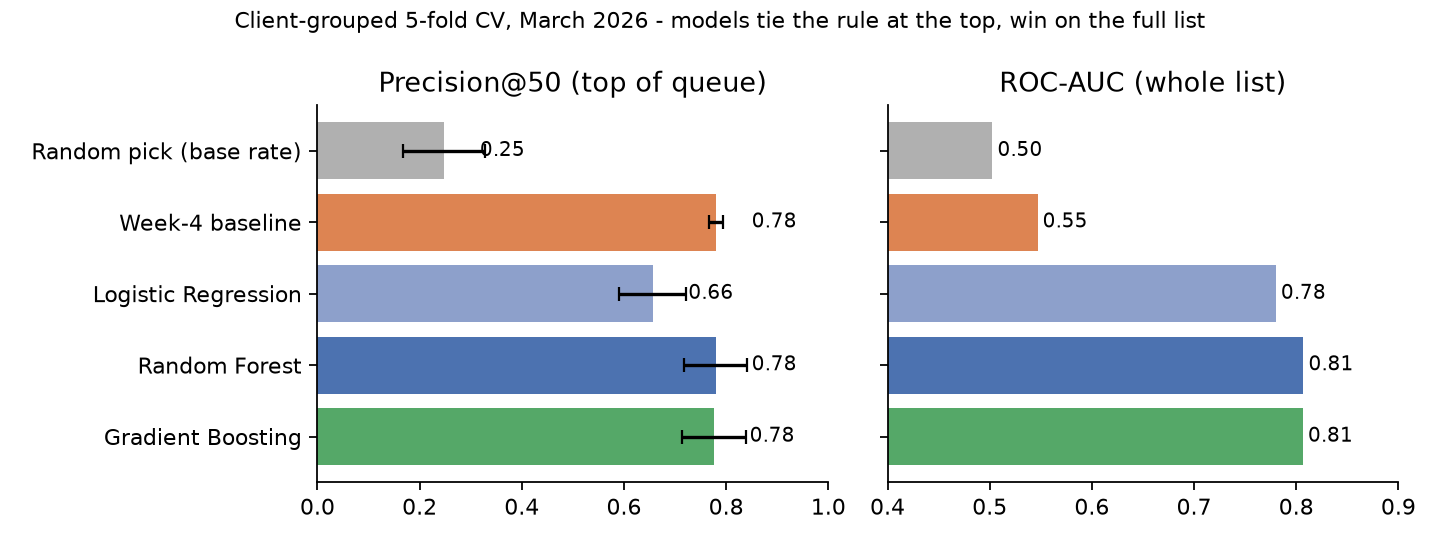

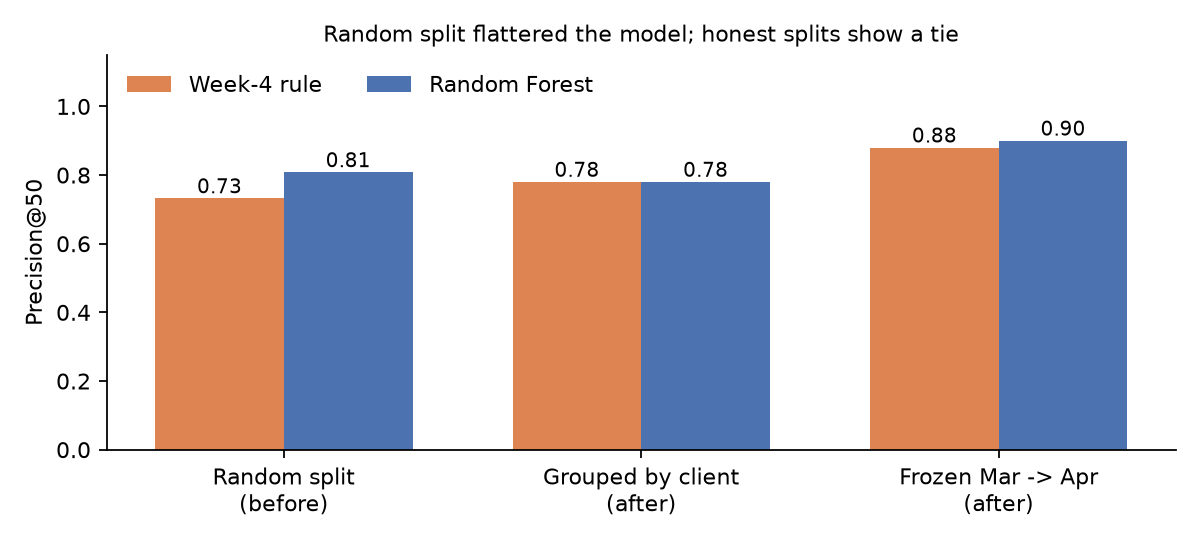

In [7]:
os.makedirs("work/figures", exist_ok=True); os.makedirs("docs/paper/img", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

# Figure 1: model vs baseline (client-grouped, P@50 with fold std, and ROC-AUC)
order = ["Random pick (base rate)", "Week-4 baseline", "Logistic Regression", "Random Forest", "Gradient Boosting"]
mm = m.reindex(order)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
cols = ["#B0B0B0", "#DD8452", "#8DA0CB", "#4C72B0", "#55A868"]
axes[0].barh(order, mm["P@50 mean"], xerr=mm["P@50 std"], color=cols, capsize=3)
axes[0].set_xlim(0, 1); axes[0].set_title("Precision@50 (top of queue)"); axes[0].invert_yaxis()
for i, val in enumerate(mm["P@50 mean"]): axes[0].text(val + 0.07, i, f"{val:.2f}", va="center", fontsize=9)
axes[1].barh(order, mm["ROC-AUC mean"], color=cols); axes[1].set_xlim(0.4, 0.9); axes[1].set_yticklabels([])
axes[1].set_title("ROC-AUC (whole list)"); axes[1].invert_yaxis()
for i, val in enumerate(mm["ROC-AUC mean"]): axes[1].text(val + 0.005, i, f"{val:.2f}", va="center", fontsize=9)
fig.suptitle("Client-grouped 5-fold CV, March 2026 - models tie the rule at the top, win on the full list", fontsize=10)
fig.tight_layout(); fig.savefig("work/figures/cap_model_vs_baseline.png", dpi=160); plt.close(fig)

# Figure 2: validation designs
v["design_short"] = v["design"].map({"BEFORE random-by-page (Mar)": "Random split\n(before)",
                                     "AFTER grouped-by-client (Mar)": "Grouped by client\n(after)",
                                     "AFTER time-forward (Mar->Apr)": "Frozen Mar -> Apr\n(after)"})
piv = v.pivot(index="design_short", columns="method", values="P50").reindex(["Random split\n(before)", "Grouped by client\n(after)", "Frozen Mar -> Apr\n(after)"])
fig, ax = plt.subplots(figsize=(7.5, 3.4)); x = np.arange(len(piv)); w = 0.36
ax.bar(x - w/2, piv["Week-4 rule"], w, label="Week-4 rule", color="#DD8452")
ax.bar(x + w/2, piv["Random Forest"], w, label="Random Forest", color="#4C72B0")
for i, (r, f) in enumerate(zip(piv["Week-4 rule"], piv["Random Forest"])):
    ax.text(i - w/2, r + 0.015, f"{r:.2f}", ha="center", fontsize=9); ax.text(i + w/2, f + 0.015, f"{f:.2f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(piv.index); ax.set_ylim(0, 1.15); ax.set_ylabel("Precision@50")
ax.set_title("Random split flattered the model; honest splits show a tie", fontsize=10)
ax.legend(frameon=False, loc="upper left", ncol=2); fig.tight_layout(); fig.savefig("work/figures/cap_validation_designs.png", dpi=160); plt.close(fig)

figs = ["cap_model_vs_baseline.png", "cap_validation_designs.png", "w07_archetype_clicks.png", "w07_precision_by_depth.png", "w07_decay_by_age.png"]
for f in figs:
    shutil.copy(f"work/figures/{f}", f"docs/paper/img/{f}")
print("Copied to docs/paper/img/:", figs)
display(Image("work/figures/cap_model_vs_baseline.png")); display(Image("work/figures/cap_validation_designs.png"))


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [x] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [x] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
